# 10장. 불용어와 전처리 파이프라인

| 항목 | 내용 |
|---|---|
| 예상 시간 | 3시간 |
| 선수 장 | 9장 |
| 이 장의 결과물 | 영어·한국어 불용어 목록과 선정 근거, `EnglishPreprocessor`, `KoreanPreprocessor`, 테스트 |
| 관련 학습 목표 | ⑤ 전처리 기준(불용어, 동의어 처리 기준)의 설계 근거 |

**학습 목표**
- 불용어가 유사도와 분류에 주는 영향을 설명할 수 있다.
- 일반 불용어 목록의 장단점(특히 부정어)을 안다.
- **문서 빈도**와 **카테고리 균등도**로 도메인 불용어 후보를 찾고, 근거를 들어 고를 수 있다.
- 길이 필터, 숫자 필터, 동의어 처리 여부를 결정하고 근거를 쓸 수 있다.
- 정제 → 토큰화 → 불용어 제거를 하나의 파이프라인으로 묶고 테스트할 수 있다.

In [1]:
# ── 7장에서 만든 데이터 로딩 코드 (src/data.py로 옮길 내용) ──
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups

PROJECT = Path.cwd().parent if Path.cwd().name == "studys" else Path.cwd()
RANDOM_STATE = 42
EN_CATEGORIES = ["comp.graphics", "comp.windows.x", "rec.sport.baseball", "rec.sport.hockey", "sci.space"]
YNAT_URL = ("https://raw.githubusercontent.com/KLUE-benchmark/KLUE/main/"
            "klue_benchmark/ynat-v1.1/ynat-v1.1_train.json")
YNAT_PATH = PROJECT / "data" / "raw" / "ynat-v1.1_train.json"

_EMAIL = re.compile(r"\S+@\S+\.\S+")
_URL = re.compile(r"(https?://|www\.)\S+")
_PHONE = re.compile(r"\b\d{2,4}[-.\s]\d{3,4}[-.\s]\d{4}\b")


def mask_pii(text: str) -> str:
    text = _EMAIL.sub(" <email> ", text)
    text = _URL.sub(" <url> ", text)
    return _PHONE.sub(" <phone> ", text)


def finalize(df: pd.DataFrame) -> pd.DataFrame:
    """개인정보 가리기 → 빈 문서 제거 → 레이블 충돌 중복·중복 제거 → 인덱스 재정렬."""
    df = df.assign(text=df["text"].map(mask_pii).str.strip())
    df = df[df["text"] != ""]
    norm = df["text"].str.split().str.join(" ")
    conflict = df.groupby(norm)["label"].transform("nunique") > 1
    df, norm = df[~conflict], norm[~conflict]
    return df[~norm.duplicated(keep="first")].reset_index(drop=True)


def load_english() -> pd.DataFrame:
    bunch = fetch_20newsgroups(subset="all", categories=EN_CATEGORIES,
                               remove=("headers", "footers", "quotes"),
                               shuffle=True, random_state=RANDOM_STATE)
    labels = [bunch.target_names[t] for t in bunch.target]
    return finalize(pd.DataFrame({"text": bunch.data, "label": labels}))


def load_korean(per_class: int = 1000) -> pd.DataFrame:
    if not YNAT_PATH.exists():
        YNAT_PATH.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(YNAT_URL, YNAT_PATH)
    raw = pd.read_json(YNAT_PATH).rename(columns={"title": "text"})[["guid", "text", "label"]]
    sampled = (raw.groupby("label", group_keys=False)
                  .sample(n=per_class, random_state=RANDOM_STATE)
                  .sample(frac=1.0, random_state=RANDOM_STATE))
    return finalize(sampled.reset_index(drop=True))

import time
from collections import Counter

from konlpy.tag import Okt

PLACEHOLDER = re.compile(r"<(?:email|url|phone)>")
EN_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*")
KO_CLEAN = re.compile(r"[^0-9a-zA-Z가-힣一-鿿\s]")
HANJA_ONLY = re.compile(r"^[一-鿿]+$")
KO_KEEP_POS = {"Noun", "Verb", "Adjective", "Alpha"}
okt = Okt()


def clean_en(text: str) -> str:   # 8장
    text = PLACEHOLDER.sub(" ", text.lower()).replace("’", "'")
    return " ".join(EN_TOKEN.findall(text))


def clean_ko(text: str) -> str:   # 8장
    return " ".join(KO_CLEAN.sub(" ", PLACEHOLDER.sub(" ", text)).split())


def tokenize_okt(text: str) -> list[str]:   # 9장
    return [w.lower() for w, p in okt.pos(clean_ko(text), norm=True, stem=True)
            if p in KO_KEEP_POS or (p == "Foreign" and HANJA_ONLY.match(w))]


en = load_english()
ko = load_korean()
t0 = time.perf_counter()
en_tokens = [clean_en(t).split() for t in en["text"]]
ko_tokens = [tokenize_okt(t) for t in ko["text"]]
print(f"영어 {len(en):,}건, 한국어 {len(ko):,}건 토큰화 ({time.perf_counter() - t0:.0f}초)")

영어 4,797건, 한국어 7,000건 토큰화 (8초)


## 10.1 불용어란 무엇이고 왜 지우나

**불용어(stopword)**는 너무 흔해서 문서를 구별하는 데 도움이 안 되는 단어입니다. 영어의 `the`, `a`, `is`, 한국어의 `하다`, `있다`, `것` 같은 단어입니다.

미니 코퍼스로 영향을 확인합니다. 불용어를 지우지 않으면 **주제가 전혀 다른 문서끼리도** `the` 하나 때문에 비슷하다고 나옵니다.

In [2]:
MINI_DOCS = [
    "The rocket launched into space!",
    "NASA launched a new space telescope.",
    "The pitcher threw a fast ball.",
    "Our team won the baseball game.",
    "Astronauts watched the baseball game in space.",
]
STOP = {"the", "a", "into", "our", "in", "new"}


def cosine_matrix(token_lists):
    vocab = sorted({t for toks in token_lists for t in toks})
    idx = {w: i for i, w in enumerate(vocab)}
    X = np.zeros((len(token_lists), len(vocab)))
    for i, toks in enumerate(token_lists):
        for t in toks:
            X[i, idx[t]] += 1
    Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
    return Xn @ Xn.T


with_stop = [d.lower().strip(".!").split() for d in MINI_DOCS]
without_stop = [[t for t in toks if t not in STOP] for toks in with_stop]

for name, toks in [("불용어 포함", with_stop), ("불용어 제거", without_stop)]:
    sim = cosine_matrix(toks)
    print(f"{name}: doc0(우주)–doc2(야구) = {sim[0, 2]:.3f}, doc0–doc3(야구) = {sim[0, 3]:.3f}, doc0–doc1(우주) = {sim[0, 1]:.3f}")

불용어 포함: doc0(우주)–doc2(야구) = 0.183, doc0–doc3(야구) = 0.183, doc0–doc1(우주) = 0.365
불용어 제거: doc0(우주)–doc2(야구) = 0.000, doc0–doc3(야구) = 0.000, doc0–doc1(우주) = 0.577


불용어를 지우면 우주 문서와 야구 문서의 유사도가 0이 되고, 같은 주제 문서의 유사도는 더 커집니다.

> **IDF가 알아서 해 주지 않나?** IDF는 흔한 단어의 가중치를 낮춰 주지만 0으로 만들지는 않습니다(smooth IDF는 최솟값이 1, 12장). 그리고 어휘 크기와 계산량도 줄어드므로 명확한 기능어는 지우는 편이 낫습니다.

## 10.2 일반 불용어 목록

영어는 NLTK가 198개짜리 목록을 제공합니다(1장에서 내려받음). 한국어는 널리 쓰이는 표준 목록이 없어서 직접 만들어야 합니다.

In [3]:
from nltk.corpus import stopwords

EN_STOP = frozenset(stopwords.words("english"))
print("NLTK 영어 불용어:", len(EN_STOP), "개")
negations = sorted(w for w in EN_STOP if w in {"no", "not", "nor", "against"} or w.endswith("n't"))
print("그중 부정 표현   :", negations)

NLTK 영어 불용어: 198 개
그중 부정 표현   : ['against', "aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't", "needn't", 'no', 'nor', 'not', "shan't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't"]


⚠️ NLTK 목록에는 `not`, `no`, `don't` 같은 **부정 표현**이 들어 있습니다. 주제 분류(우주냐 야구냐)에는 문제가 없지만, "works"와 "does not work"의 의미 차이는 사라집니다. 이 과제에서는 그대로 쓰되, 21장 BoW 한계 분석에서 사례로 다룹니다. 감성 분석처럼 부정이 중요한 작업이라면 부정어를 목록에서 빼야 합니다.

## 10.3 데이터에서 도메인 불용어 찾기 ⭐

일반 목록에 없는데도 **이 데이터에서** 흔하고 쓸모없는 단어가 있습니다. 영어 게시판 글의 `would`, `like`, `know` 같은 단어입니다. 감으로 고르지 않고 **두 가지 숫자**로 후보를 찾습니다.

**① 문서 빈도 비율 (DF ratio)** = 단어가 나온 문서 수 ÷ 전체 문서 수. 높을수록 흔한 단어입니다.

**② 카테고리 균등도 (evenness)**: 단어가 카테고리들 사이에 얼마나 **고르게** 퍼져 있는지를 0~1로 나타냅니다.
1. 카테고리 $k$마다 "그 카테고리 문서 중 이 단어가 나온 비율" $r_k$를 구합니다 (카테고리 크기 차이 보정).
2. 합이 1이 되도록 $p_k = r_k / \sum_j r_j$로 바꿉니다.
3. **정규화 엔트로피** $E = -\dfrac{\sum_k p_k \ln p_k}{\ln K}$ ($K$ = 카테고리 수)

$E = 1$이면 모든 카테고리에 똑같이 나오고(주제를 가르지 못함), $E$가 0에 가까우면 한 카테고리에 몰려 있습니다(강한 주제 신호).

In [4]:
def stopword_candidates(token_lists, labels, min_df_ratio: float = 0.02) -> pd.DataFrame:
    labels = pd.Series(labels).reset_index(drop=True)
    classes = sorted(labels.unique())
    class_size = labels.value_counts()[classes].to_numpy()
    rows: dict[str, np.ndarray] = {}
    for toks, lab in zip(token_lists, labels):
        k = classes.index(lab)
        for t in set(toks):
            rows.setdefault(t, np.zeros(len(classes)))[k] += 1
    words = list(rows)
    counts = np.array([rows[w] for w in words])                 # (단어 수, 카테고리 수) 문서 빈도
    df_ratio = counts.sum(axis=1) / len(labels)
    rate = counts / class_size                                  # 카테고리 크기 보정
    p = rate / rate.sum(axis=1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        ent = -np.where(p > 0, p * np.log(p), 0.0).sum(axis=1) / np.log(len(classes))
    out = pd.DataFrame({"word": words, "df_ratio": df_ratio, "evenness": ent})
    return out[out["df_ratio"] >= min_df_ratio].sort_values("df_ratio", ascending=False).reset_index(drop=True)


en_after_nltk = [[t for t in toks if t not in EN_STOP] for toks in en_tokens]
en_cand = stopword_candidates(en_after_nltk, en["label"])
print("영어 (NLTK 불용어 제거 후) 문서 빈도 상위 25개")
print(en_cand.head(25).round(3).to_string(index=False))

영어 (NLTK 불용어 제거 후) 문서 빈도 상위 25개
  word  df_ratio  evenness
 would     0.270     0.994
   one     0.233     0.995
  like     0.223     0.998
   get     0.200     0.993
  know     0.188     0.994
 think     0.161     0.954
  also     0.160     0.990
  time     0.159     0.987
     x     0.158     0.552
 could     0.153     0.991
  well     0.138     0.978
   use     0.135     0.834
  good     0.132     0.968
 first     0.130     0.971
  much     0.129     0.987
   see     0.127     0.982
thanks     0.124     0.844
anyone     0.121     0.952
   way     0.120     0.993
  last     0.120     0.886
   two     0.118     0.982
  game     0.117     0.537
  even     0.110     0.975
  year     0.108     0.813
   new     0.107     0.987


문서 빈도가 높은 단어들 중에서도 균등도가 다릅니다. 두 축으로 그려 보면 구분이 분명합니다.

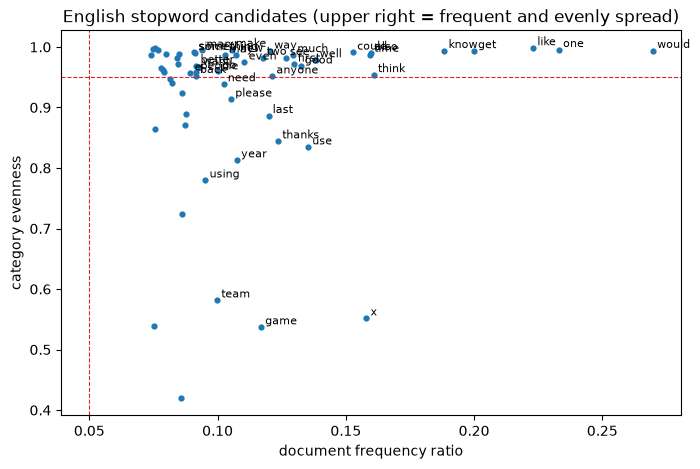

In [5]:
import matplotlib.pyplot as plt

top = en_cand.head(60)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(top["df_ratio"], top["evenness"], s=12)
for _, r in top.head(40).iterrows():
    ax.annotate(r["word"], (r["df_ratio"], r["evenness"]), fontsize=8, xytext=(3, 2), textcoords="offset points")
ax.axhline(0.95, color="tab:red", lw=0.8, ls="--")
ax.axvline(0.05, color="tab:red", lw=0.8, ls="--")
ax.set_xlabel("document frequency ratio")
ax.set_ylabel("category evenness")
ax.set_title("English stopword candidates (upper right = frequent and evenly spread)")
plt.show()

- **오른쪽 위**(DF 5% 이상, 균등도 0.95 이상): 흔하면서 모든 게시판에 고르게 나오는 단어 → **불용어 후보**
- **아래쪽**: 흔하지만 특정 게시판에 몰린 단어(`game`, `space`, `team` 등) → **주제 신호이므로 절대 지우면 안 됨**

기준선(5%, 0.95)은 그림을 보고 정한 값입니다. 후보를 뽑은 뒤에는 **사람이 한 번 더 판단**합니다. 기준을 넘었어도 검색어로 쓰일 수 있는 **내용어**(`time`, `people`, `new`)는 남깁니다.

In [6]:
auto = en_cand[(en_cand["df_ratio"] >= 0.05) & (en_cand["evenness"] >= 0.95)]
print(f"기준을 넘은 후보 {len(auto)}개:")
print(auto["word"].tolist())

print("\nDF는 높지만 균등도가 낮은 단어 (주제 신호, 유지):")
print(en_cand[(en_cand["df_ratio"] >= 0.05) & (en_cand["evenness"] < 0.8)][["word", "df_ratio", "evenness"]]
      .head(10).round(3).to_string(index=False))

기준을 넘은 후보 84개:
['would', 'one', 'like', 'get', 'know', 'think', 'also', 'time', 'could', 'well', 'good', 'first', 'much', 'see', 'anyone', 'way', 'two', 'even', 'new', 'make', 'may', 'go', 'many', 'want', 'better', 'people', 'back', 'something', 'since', 'e', 'right', 'really', 'still', 'got', 'going', 'might', 'say', "can't", 'another', 'look', 'point', 'sure', 'best', 'take', 'probably', 'give', 'lot', 'etc', 'around', 'things', 'someone', 'made', 'however', 'line', 'actually', 'number', 'least', "that's", 'put', 'little', 'name', 'post', 'thing', 'far', 'able', 'second', 'read', 'enough', 'without', 'though', 'come', 'never', 'either', 'b', 'different', 'course', 'every', 'done', 'end', 'maybe', 'must', 'believe', 'three', 'part']

DF는 높지만 균등도가 낮은 단어 (주제 신호, 유지):
    word  df_ratio  evenness
       x     0.158     0.552
    game     0.117     0.537
    team     0.100     0.581
   using     0.095     0.780
 program     0.086     0.724
   space     0.086     0.420
   games     0.075  

후보 목록에서 조동사, 일반 동사, 부사, 대명사처럼 **내용이 없는 단어만** 골라 도메인 불용어로 정합니다. 아래 목록은 이런 판단으로 고른 예입니다. `cant`는 10.4절에서 아포스트로피를 지운 뒤의 형태라, 이 표에는 `can't`로 나타나고 `cant`는 `NaN`(후보 없음)으로 보입니다.

In [7]:
DOMAIN_STOPWORDS_EN = frozenset({
    "would", "could", "might", "may", "also", "like", "get", "got", "go", "going", "know", "think",
    "see", "say", "make", "want", "look", "one", "well", "much", "many", "even", "way", "something",
    "anyone", "since", "still", "really", "right", "another", "cant",
})
check = en_cand.set_index("word").reindex(sorted(DOMAIN_STOPWORDS_EN))[["df_ratio", "evenness"]].round(3)
print("고른 도메인 불용어의 수치:")
print(check.T.to_string())

kept = sorted(set(auto["word"]) - DOMAIN_STOPWORDS_EN)
print("\n기준을 넘었지만 남긴 단어 (내용어):", kept)

고른 도메인 불용어의 수치:
word      also  another  anyone  cant  could   even    get    go  going    got   know   like   look   make   many    may  might   much    one  really  right    say    see  since  something  still  think   want    way   well  would
df_ratio  0.16    0.075   0.121   NaN  0.153  0.110  0.200  0.10  0.079  0.080  0.188  0.223  0.075  0.105  0.094  0.103  0.079  0.129  0.233   0.085  0.085  0.078  0.127  0.091      0.091  0.084  0.161  0.093  0.120  0.138  0.270
evenness  0.99    0.998   0.952   NaN  0.991  0.975  0.993  0.96  0.959  0.988  0.994  0.998  0.996  0.996  0.994  0.986  0.961  0.987  0.995   0.971  0.988  0.965  0.982  0.991      0.990  0.982  0.954  0.966  0.993  0.978  0.994

기준을 넘었지만 남긴 단어 (내용어): ['able', 'actually', 'around', 'b', 'back', 'believe', 'best', 'better', "can't", 'come', 'course', 'different', 'done', 'e', 'either', 'end', 'enough', 'etc', 'every', 'far', 'first', 'give', 'good', 'however', 'least', 'line', 'little', 'lot', 'made', 'maybe', 'must

남긴 단어 중에는 `probably`, `however`, `actually`처럼 기능어 성격의 단어도 있습니다. 어디까지 지울지는 판단의 문제입니다. 10.6절에서 보듯 불용어를 더 지워도 분류 성능 차이는 작으므로, 여기서는 **확실히 내용이 없는 단어만** 보수적으로 지웠습니다. 한 글자인 `b`, `e`는 10.4절 길이 필터로 빠지고, `that's`는 `'s`를 떼면 NLTK 불용어 `that`이 되어 자동으로 빠집니다.

### 한국어 도메인 불용어
같은 방법을 Okt 토큰에 적용합니다. 한국어는 일반 목록이 없으므로 이 결과가 곧 불용어 목록의 출발점입니다.

In [8]:
ko_cand = stopword_candidates(ko_tokens, ko["label"], min_df_ratio=0.005)
print("한국어 문서 빈도 상위 25개")
print(ko_cand.head(25).round(3).to_string(index=False))

한국어 문서 빈도 상위 25개
word  df_ratio  evenness
  하다     0.092     0.960
  종합     0.091     0.942
 대통령     0.040     0.330
  한국     0.034     0.968
   美     0.028     0.408
   北     0.026     0.248
  삼성     0.025     0.650
   위     0.025     0.950
 게시판     0.023     0.724
  출시     0.022     0.401
   첫     0.021     0.940
  kt     0.021     0.602
   명     0.021     0.744
  lg     0.021     0.594
   g     0.020     0.413
   등     0.019     0.993
   보     0.019     0.883
   전     0.018     0.817
  되다     0.017     0.964
   중     0.016     0.919
   것     0.016     0.955
  감독     0.016     0.118
   中     0.016     0.495
  이란     0.015     0.140
  sk     0.015     0.635


In [9]:
print("균등도 0.9 이상 후보:")
print(ko_cand[ko_cand["evenness"] >= 0.9][["word", "df_ratio", "evenness"]].head(25).round(3).to_string(index=False))

균등도 0.9 이상 후보:
word  df_ratio  evenness
  하다     0.092     0.960
  종합     0.091     0.942
  한국     0.034     0.968
   위     0.025     0.950
   첫     0.021     0.940
   등     0.019     0.993
  되다     0.017     0.964
   중     0.016     0.919
   것     0.016     0.955
  없다     0.014     0.972
   개     0.014     0.924
  개최     0.013     0.971
  최고     0.012     0.937
   제     0.010     0.935
  지원     0.010     0.901
  보다     0.010     0.914
  있다     0.009     0.982
   차     0.009     0.955
   새     0.009     0.912
  내년     0.008     0.901
  않다     0.008     0.951
  올해     0.008     0.912
   후     0.008     0.935
   속     0.008     0.912
  오다     0.008     0.947


후보를 성격별로 나눠 판단합니다.

| 유형 | 예 | 판단 |
|---|---|---|
| 기능 용언 (`stem=True`로 원형이 된 것) | 하다, 되다, 있다, 없다, 이다, 않다 | 지움 |
| 의존명사·나열어 | 등, 것, 수, 중, 및, 때, 후, 내 | 지움 |
| Okt가 조사를 명사로 잘못 자른 조각 | 의, 로 | 지움 |
| 기사 제목 형식어 | 종합 (`…출격종합`처럼 기사 버전 표시) | 지움 |
| 균등하지만 내용어 | 한국 | **남김** (검색어로 쓰일 수 있음) |

In [10]:
STOPWORDS_KO = frozenset({
    "하다", "되다", "있다", "없다", "이다", "않다",
    "등", "것", "수", "중", "및", "때", "후", "내", "듯", "제", "개",
    "의", "로",
    "종합",
})
check_ko = ko_cand.set_index("word").reindex(sorted(STOPWORDS_KO))[["df_ratio", "evenness"]].round(3)
print(check_ko.T.to_string())

word          개      것      내     되다      듯      등   때      로   및      수     않다     없다   의     이다     있다      제     종합      중     하다      후
df_ratio  0.014  0.016  0.005  0.017  0.007  0.019 NaN  0.006 NaN  0.006  0.008  0.014 NaN  0.006  0.009  0.010  0.091  0.016  0.092  0.008
evenness  0.924  0.955  0.924  0.964  0.953  0.993 NaN  0.901 NaN  0.987  0.951  0.972 NaN  0.944  0.982  0.935  0.942  0.919  0.960  0.935


`NaN`인 단어는 문서 빈도가 기준(0.5%)보다 낮아 후보 표에 없던 단어입니다. 수치가 낮아도 **성격이 같은 기능어**라 함께 넣은 것입니다. 이렇게 "수치 + 언어적 판단"을 함께 적는 것이 좋은 근거입니다.

## 10.4 길이 필터와 숫자 필터

불용어 외에도 걸러야 할 토큰이 있습니다.

In [11]:
en_vocab = Counter(t for toks in en_after_nltk for t in toks)
longest = sorted(en_vocab, key=len, reverse=True)[:8]
print("가장 긴 영어 토큰:")
for w in longest:
    print(f"  {len(w):>3}자 {w[:60]}{'...' if len(w) > 60 else ''}")

short = [w for w in en_vocab if len(w) < 2]
print("\n한 글자 토큰:", sorted(short), "→ 총", sum(en_vocab[w] for w in short), "회")

가장 긴 영어 토큰:
   79자 aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaauuuuuuuuuuuuuuuuuuuuuuuuuuuuu...
   42자 smoke'embake'emdominatebysheerintimidation
   32자 xtdisplaystringconversionwarning
   31자 xtgetselectionvaluesincremental
   30자 xmptablemakerowsfitqueryheight
   30자 virtualdesktopbackgroundpixmap
   30자 xtgetselectionvalueincremental
   29자 xmptablemakecolsfitquerywidth

한 글자 토큰: ['b', 'c', 'e', 'f', 'g', 'h', 'j', 'k', 'l', 'n', 'p', 'q', 'r', 'u', 'v', 'w', 'x', 'z'] → 총 21403 회


- **너무 긴 토큰**: `comp.graphics`에는 그림 파일을 텍스트로 인코딩(uuencode)해서 본문에 붙인 글이 있습니다. 그 조각이 의미 없는 긴 "단어" 수천 개가 됩니다. 영어 단어는 20자를 넘는 일이 드물므로 **20자 초과 토큰을 지웁니다.** 대가로 `comp.windows.x`의 긴 함수 이름(`xtgetselectionvalueincremental` 등)도 함께 지워집니다. 이런 이름은 글마다 달라 주제 신호로서 가치가 크지 않다고 보고 받아들였습니다.
- **한 글자 토큰**: 8장 정제에서 생긴 조각(`3D` → `d`, `X11R5` → `x`, `r`)과 `s`, `t` 같은 잔해입니다. **2글자 미만 토큰을 지웁니다.**
- **소유격 `'s`**: `nasa's`와 `nasa`를 합치기 위해 `'s`를 떼고, 남은 아포스트로피는 지웁니다(`can't` → `cant`). NLTK 목록에 `don't` 같은 축약형이 있으므로 **불용어 검사를 먼저 하고 아포스트로피를 지웁니다.** 순서를 바꾸면 `dont`가 불용어 목록에 걸리지 않습니다.
- **한국어 숫자 토큰**: 9장 품사 필터에서 `Number`는 빠지지만, 형태소 분석기가 숫자를 다른 품사로 붙이는 경우를 대비해 숫자로만 된 토큰을 한 번 더 지웁니다.

**너무 드문 단어**(한 문서에만 나온 단어)는 여기서 지우지 않고 11장에서 `min_df`로 처리합니다. 토큰 단계가 아니라 어휘를 만드는 단계의 설정이기 때문입니다.

## 10.5 동의어와 표기 통일

같은 대상을 다른 단어로 쓰는 경우가 있습니다.

In [12]:
pairs = [("北", "북한"), ("美", "미국"), ("中", "중국"), ("與", "여당")]
ko_df = Counter(t for toks in ko_tokens for t in set(toks))
for a, b in pairs:
    print(f"{a}: {ko_df[a]:>3}개 문서   {b}: {ko_df[b]:>3}개 문서")

北: 183개 문서   북한:  71개 문서
美: 196개 문서   미국:  71개 문서
中: 109개 문서   중국:  75개 문서
與:  45개 문서   여당:   8개 문서


`北`과 `북한`은 같은 뜻인데 다른 열이라, "북한" 검색으로 `北`만 쓴 제목을 찾지 못합니다. 선택지는 두 가지입니다.

| 선택 | 방법 | 장점 | 단점 |
|---|---|---|---|
| **적용하지 않음** | 그대로 둔다 | 단순하고 임의 판단이 없다 | 동의어로 쓴 문서를 놓친다 |
| 동의어 사전 적용 | `{"北": "북한", "美": "미국"}`으로 토큰 치환 | 해당 쌍은 해결 | 사전을 만들고 관리해야 하고, 빠진 쌍은 여전히 문제. `中`은 "중국"이 아니라 "가운데"일 수도 있다 |

이 자료에서는 **적용하지 않는 쪽**을 택하고, 생기는 문제를 21장 BoW 한계에서 사례로 보여 줍니다. 동의어 문제는 BoW의 근본 한계(단어가 다르면 무조건 다른 차원)이고, 사전으로 일부만 고치기보다 **한계로 분석하는 것이 과제 의도**에 맞기 때문입니다. 사전을 적용하기로 했다면 그 근거와 효과를 측정해서 쓰면 됩니다.

## 10.6 불용어 제거 효과 측정

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split


def quick_eval(token_lists, labels) -> dict:
    """미리 보기: 어휘 통계와 분류 F1 (17–18장에서 직접 만든다)."""
    labels = np.asarray(labels)
    tr, te = train_test_split(np.arange(len(labels)), test_size=0.2, stratify=labels, random_state=RANDOM_STATE)
    vec = TfidfVectorizer(analyzer=lambda t: t, min_df=2)
    X_tr = vec.fit_transform([token_lists[i] for i in tr])
    pred = LogisticRegression(max_iter=1000).fit(X_tr, labels[tr]).predict(vec.transform([token_lists[i] for i in te]))
    return {"어휘 수 (min_df=2)": len(vec.vocabulary_),
            "문서당 토큰 수": round(np.mean([len(t) for t in token_lists]), 1),
            "macro F1 (미리 보기)": round(f1_score(labels[te], pred, average="macro"), 3)}


EN_ALL_STOP = EN_STOP | DOMAIN_STOPWORDS_EN
en_full = [[t.removesuffix("'s").replace("'", "") for t in toks if t not in EN_ALL_STOP] for toks in en_tokens]
en_full = [[t for t in toks if 2 <= len(t) <= 20 and t not in EN_ALL_STOP] for toks in en_full]
ko_full = [[t for t in toks if t not in STOPWORDS_KO and not t.isdigit()] for toks in ko_tokens]

pd.DataFrame({
    "영어: 정제만": quick_eval(en_tokens, en["label"]),
    "영어: + NLTK": quick_eval(en_after_nltk, en["label"]),
    "영어: + 도메인 + 길이": quick_eval(en_full, en["label"]),
    "한국어: Okt": quick_eval(ko_tokens, ko["label"]),
    "한국어: + 불용어": quick_eval(ko_full, ko["label"]),
}).T

,어휘 수 (min_df=2),문서당 토큰 수,macro F1 (미리 보기)
영어: 정제만,16931.0,178.4,0.880
영어: + NLTK,16754.0,106.3,0.887
영어: + 도메인 + 길이,16425.0,95.7,0.880
한국어: Okt,5502.0,8.4,0.767
한국어: + 불용어,5482.0,8.0,0.770


불용어를 지우면 **문서당 토큰 수가 크게 줄어** 계산이 가벼워집니다. 분류 F1은 크게 달라지지 않거나 조금 변합니다. 로지스틱 회귀는 흔한 단어에 작은 가중치를 주는 법을 스스로 배우기 때문입니다.

그렇다면 불용어 제거는 쓸모없을까요? 아닙니다. **검색**에서는 쿼리와 문서에 공통으로 들어간 기능어가 코사인 유사도를 직접 흐리고(10.1절), 분류 결과를 **설명할 때** 기능어가 상위 단어로 올라오면 해석이 어렵습니다. 리포트에는 이렇게 "분류 점수에는 큰 영향이 없었지만, 검색 유사도와 해석에서 이점이 있다"처럼 **측정 결과에 맞게** 써야 합니다.

## 10.7 전처리 파이프라인으로 묶기

지금까지 정한 규칙을 하나의 객체로 묶습니다. 호출하면 원문을 받아 토큰 리스트를 돌려주도록 `__call__`을 씁니다. 이렇게 하면 문서와 검색어에 **똑같은 전처리**를 적용하기 쉽습니다(16장).

```
원문 → (7장) 개인정보 가리기 → (8장) 정제 → (9장) 토큰화 → (10장) 불용어·길이·숫자 필터 → 토큰 리스트
```

In [14]:
class EnglishPreprocessor:
    def __init__(self, use_domain_stopwords: bool = True, min_len: int = 2, max_len: int = 20):
        self.stopwords = EN_STOP | (DOMAIN_STOPWORDS_EN if use_domain_stopwords else frozenset())
        self.min_len, self.max_len = min_len, max_len

    def __call__(self, text: str) -> list[str]:
        tokens = []
        for tok in clean_en(text).split():
            if tok in self.stopwords:                      # 축약형(don't)을 먼저 거른다
                continue
            tok = tok.removesuffix("'s").replace("'", "")  # nasa's → nasa, can't → cant
            if self.min_len <= len(tok) <= self.max_len and tok not in self.stopwords:
                tokens.append(tok)
        return tokens


class KoreanPreprocessor:
    def __init__(self, tokenizer: str = "okt", use_stopwords: bool = True):
        if tokenizer not in ("okt", "whitespace"):
            raise ValueError(f"tokenizer는 'okt' 또는 'whitespace': {tokenizer}")
        self.tokenizer = tokenizer
        self.stopwords = STOPWORDS_KO if use_stopwords else frozenset()

    def __call__(self, text: str) -> list[str]:
        tokens = tokenize_okt(text) if self.tokenizer == "okt" else clean_ko(text).lower().split()
        return [t for t in tokens if t not in self.stopwords and not t.isdigit()]


en_pre = EnglishPreprocessor()
ko_pre = KoreanPreprocessor("okt")
print(en_pre("NASA's new rocket didn't launch; it would cost $1.5B in 1993."))
print(ko_pre("삼성전자가 3분기 사상 최대 실적을 발표했다…종합"))
print(KoreanPreprocessor("whitespace")("삼성전자가 3분기 사상 최대 실적을 발표했다…종합"))

['nasa', 'new', 'rocket', 'launch', 'cost']
['전자', '사상', '최대', '실적', '발표']
['삼성전자가', '3분기', '사상', '최대', '실적을', '발표했다']


한국어 첫 예시에서 `삼성`이 빠진 것은 9.5절에서 본 Okt의 오분석(`삼`, `성`을 수식어로 분석) 때문입니다. 공백 토큰화 결과와 비교하면 형태소 분석이 늘 이기는 것은 아니라는 점이 보입니다. 리포트의 한계 분석에 적어 둘 만한 사례입니다.

### 테스트
규칙이 의도대로 동작하는지 테스트로 고정해 둡니다. 나중에 규칙을 고쳤을 때 다른 부분이 깨지지 않았는지 바로 알 수 있습니다. 아래 함수들은 그대로 `tests/test_preprocess.py`에 옮기면 pytest가 실행합니다(2장).

In [15]:
def test_en_lowercase_and_possessive():
    assert en_pre("NASA's Shuttle") == ["nasa", "shuttle"]


def test_en_contraction_is_stopword():
    assert "dont" not in en_pre("I don't know") and "don" not in en_pre("I don't know")


def test_en_numbers_and_short_tokens_removed():
    assert en_pre("3D graphics in 1993") == ["graphics"]


def test_en_long_token_removed():
    assert en_pre("x" * 25 + " orbit") == ["orbit"]


def test_ko_particles_and_stopwords_removed():
    tokens = ko_pre("정부가 대책을 발표했다")
    assert "정부" in tokens and "가" not in tokens and "하다" not in tokens


def test_ko_hanja_kept():
    assert "北" in ko_pre("北 미사일 발사")


def test_ko_digits_removed():
    assert all(not t.isdigit() for t in ko_pre("2024년 3분기 실적"))


tests = [f for name, f in list(globals().items()) if name.startswith("test_") and callable(f)]
for t in tests:
    try:
        t()
        print("✅", t.__name__)
    except AssertionError:
        print("❌", t.__name__)

✅ test_en_lowercase_and_possessive
✅ test_en_contraction_is_stopword
✅ test_en_numbers_and_short_tokens_removed
✅ test_en_long_token_removed
✅ test_ko_particles_and_stopwords_removed
✅ test_ko_hanja_kept
✅ test_ko_digits_removed


## 📝 리포트용 정리: 불용어·필터·동의어 기준 (학습 목표 ⑤)

| 항목 | 영어 | 한국어 | 근거 |
|---|---|---|---|
| 일반 불용어 | NLTK english 198개 | 없음 (표준 목록 없음) | 기능어 제거. NLTK에 부정어가 포함됨을 인지 |
| 도메인 불용어 | 31개 (would, like, know …) | 20개 (하다, 있다, 등, 것, 종합 …) | DF 비율 + 카테고리 균등도로 후보를 찾고, 내용어는 사람이 판단해 제외 |
| 길이 필터 | 2자 미만, 20자 초과 제거 | 없음 | 정제 잔해(`d`, `x`)와 인코딩된 파일 조각 제거 |
| 숫자 | 정제에서 제거 | 숫자만 있는 토큰 제거 | 8장과 같음 |
| 소유격·축약 | `'s` 제거, 아포스트로피 삭제 (불용어 검사 후) | 해당 없음 | `nasa's`와 `nasa` 통합 |
| 동의어 | 처리 안 함 | 처리 안 함 (`北`/`북한`) | BoW 한계로 분석 (21장) |
| 효과 | 문서당 토큰 수 감소, F1 변화 작음 | 같음 | 10.6 측정표 |

## ✍️ 실습: 불용어 효과를 검색 관점에서 확인하기

미니 코퍼스로 다음을 해 보세요.
1. 쿼리 `"the space game"`을 불용어 제거 **전/후** 토큰으로 만든다.
2. 각각에 대해 미니 코퍼스 5개 문서와의 코사인 유사도를 계산한다(위의 `cosine_matrix`를 참고해 쿼리용으로 바꾸거나, 쿼리를 6번째 문서로 넣어 계산).
3. 불용어 제거 전에 쿼리와 유사도가 0보다 컸던 **야구 문서**가 제거 후 어떻게 바뀌는지 확인한다.

In [16]:
# 여기에 작성하세요

**정답**

In [17]:
query = "the space game"
for name, docs in [("불용어 포함", with_stop), ("불용어 제거", without_stop)]:
    q = query.split() if name == "불용어 포함" else [t for t in query.split() if t not in STOP]
    sim = cosine_matrix(docs + [q])[-1, :-1]          # 마지막 행 = 쿼리와 각 문서의 유사도
    print(f"{name} (쿼리 토큰 {q})")
    for i, s in enumerate(sim):
        print(f"  doc {i} [{['space', 'space', 'baseball', 'baseball', 'space'][i]:<8}] {s:.3f}  {MINI_DOCS[i]}")

불용어 포함 (쿼리 토큰 ['the', 'space', 'game'])
  doc 0 [space   ] 0.516  The rocket launched into space!
  doc 1 [space   ] 0.236  NASA launched a new space telescope.
  doc 2 [baseball] 0.236  The pitcher threw a fast ball.
  doc 3 [baseball] 0.471  Our team won the baseball game.
  doc 4 [space   ] 0.655  Astronauts watched the baseball game in space.
불용어 제거 (쿼리 토큰 ['space', 'game'])
  doc 0 [space   ] 0.408  The rocket launched into space!
  doc 1 [space   ] 0.354  NASA launched a new space telescope.
  doc 2 [baseball] 0.000  The pitcher threw a fast ball.
  doc 3 [baseball] 0.354  Our team won the baseball game.
  doc 4 [space   ] 0.632  Astronauts watched the baseball game in space.


불용어를 포함하면 `the`만 겹치는 doc 2(투수 이야기)도 0보다 큰 점수를 받습니다. 제거하면 doc 2는 0이 되고, 실제로 `space`나 `game`을 가진 문서만 남습니다.

## 🧐 퀴즈

**Q1.** 불용어 후보를 고를 때 문서 빈도만 보면 안 되는 이유는? 예를 들어 보세요.
<details><summary>▶ 정답 보기</summary>

문서 빈도가 높아도 특정 카테고리에 몰린 단어는 강한 주제 신호이기 때문입니다. 예를 들어 `game`은 흔하지만 야구·하키 게시판에 몰려 있어서, 지우면 스포츠 분류 성능이 떨어집니다. 그래서 카테고리 균등도를 함께 봅니다.
</details>

**Q2.** 카테고리 균등도를 계산할 때 단어의 문서 수를 그대로 쓰지 않고 카테고리 크기로 나누는 이유는?
<details><summary>▶ 정답 보기</summary>

카테고리마다 문서 수가 다르면, 큰 카테고리에 단어가 많이 나오는 것이 단지 문서가 많아서일 수 있기 때문입니다. "그 카테고리 문서 중 몇 %에 나왔나"로 바꿔야 공정하게 비교할 수 있습니다.
</details>

**Q3.** 영어 파이프라인에서 불용어 검사를 아포스트로피 제거보다 먼저 하는 이유는?
<details><summary>▶ 정답 보기</summary>

NLTK 불용어 목록에는 `don't`처럼 아포스트로피가 있는 축약형이 들어 있습니다. 아포스트로피를 먼저 지우면 `dont`가 되어 목록에 걸리지 않고 남습니다.
</details>

**Q4.** NLTK 불용어 목록을 그대로 쓸 때 주의할 점은?
<details><summary>▶ 정답 보기</summary>

`not`, `no`, `don't` 같은 부정 표현이 들어 있어 "works"와 "does not work"의 차이가 사라집니다. 주제 분류에는 영향이 작지만, 부정이 중요한 작업에서는 목록에서 빼야 하고, 리포트의 한계 분석에 적어야 합니다.
</details>

**Q5.** 불용어를 제거해도 분류 F1이 크게 오르지 않았다면, 불용어 제거는 의미가 없는 걸까요?
<details><summary>▶ 정답 보기</summary>

아닙니다. 분류 모델은 흔한 단어에 작은 가중치를 스스로 배우지만, 검색의 코사인 유사도는 공통 기능어 때문에 직접 흐려지고, 분류 근거를 설명할 때 기능어가 섞이면 해석이 어렵습니다. 계산량과 메모리도 줄어듭니다. 측정 결과를 있는 그대로 쓰고 이런 이점을 근거로 들면 됩니다.
</details>

## ✅ 체크포인트
- [ ] 불용어가 코사인 유사도에 주는 영향을 예로 보여 줄 수 있다.
- [ ] DF 비율과 카테고리 균등도로 불용어 후보를 뽑을 수 있다.
- [ ] 후보 중 지울 단어와 남길 단어를 근거와 함께 고를 수 있다.
- [ ] 길이·숫자 필터와 동의어 처리 여부를 결정하고 설명할 수 있다.
- [ ] 전처리 파이프라인 클래스와 테스트를 만들 수 있다.

## 🔗 과제 연결과 다음 장
- `EnglishPreprocessor`, `KoreanPreprocessor`, 불용어 목록은 `src/preprocess.py`가 되고, 테스트는 `tests/test_preprocess.py`가 됩니다. 불용어 후보 계산은 `src/stopword_analysis.py`로 옮겨 근거를 재현할 수 있게 합니다.
- 리포트용 정리표는 README "전처리 파이프라인과 설계 근거"에 씁니다(학습 목표 ⑤).
- Part 3(데이터 준비와 전처리)가 끝났습니다. **11장. Bag of Words**부터 토큰 리스트를 숫자 행렬로 바꿉니다.